# Multivariate Statistical Process Control (MSPC): PCA, Hotelling's $T^2$ & $Q$ Statistic
In this notebook, we monitor all 314 cleaned sensors simultaneously using Principal Component Analysis (PCA). We standardize the data and fit PCA exclusively on the Phase I `In-Control` baseline, project Phase II batches onto the PCA model, and monitor the production line using two complementary multivariate charts: Hotelling's $T^2$ (variation inside the PCA model) and the $Q$ / SPE statistic (residual error outside the PCA model). Finally, we use Contribution Plots to diagnose which specific sensors cause an alarm.

In [131]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import f, chi2

## 1. Loading the Cleaned Dataset & Phase I Standardization
We load `data/secom_cleaned.csv`, split the batches into Phase I (`In-Control`) and Phase II, and standardize all 314 sensors. We use `scaler.fit_transform()` on Phase I `In-Control` to learn the baseline mean ($\mu_0$) and standard deviation ($\sigma_0$) of each sensor, and then apply `scaler.transform()` on Phase II so that Phase II is evaluated against the Phase I baseline.

In [132]:
df = pd.read_csv('../data/secom_cleaned.csv')
sensor_cols = [s for s in df.columns if s.startswith('Sensor_')]
df_p1 = df[df['Phase'] == 'Phase I'].copy()
df_p1_ic = df_p1[df_p1['Defect'] == 0].copy().reset_index(drop=True)
df_p2 = df[df['Phase'] == 'Phase II'].copy().reset_index(drop=True)

In [133]:
# Standardization fitted strictly on In-Control Phase I
scaler = StandardScaler()
X_p1_ic_scaled = scaler.fit_transform(df_p1_ic[sensor_cols])
X_p2_scaled = scaler.transform(df_p2[sensor_cols])

## 2. Dimensionality Reduction with PCA
Next, we fit PCA on the standardized Phase I `In-Control` data and select the number of principal components $k$ required to explain at least 80% of the total process variance ($k = 87$ out of 314 sensors). We then project Phase II onto these $k$ principal components using `pca.transform(X_p2_scaled)`.

In [134]:
pca_full = PCA()
pca_full.fit(X_p1_ic_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

k = int(np.argmax(cum_var >= 0.8) + 1)
print(f'Number of principal components to explain 80% variance: k = {k}')

pca = PCA(n_components=k)
T_p1_ic = pca.fit_transform(X_p1_ic_scaled)
T_p2 = pca.transform(X_p2_scaled)
eigenvalues = pca.explained_variance_

Number of principal components to explain 80% variance: k = 87


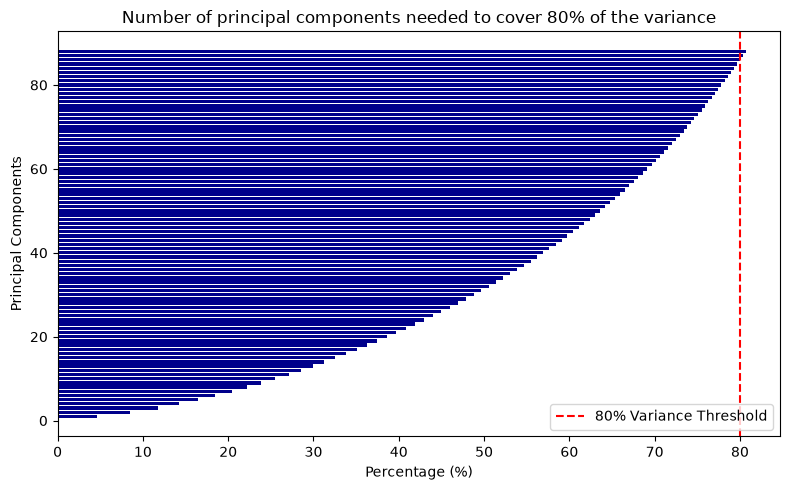

In [141]:
plt.figure(figsize=(8, 5))
plt.barh(range(1, k + 2), cum_var[0:k + 1] * 100, color='darkblue')
plt.axvline(80, linestyle='--', color='red', label='80% Variance Threshold')
plt.xlabel('Percentage (%)')
plt.ylabel('Principal Components')
plt.title('Number of principal components needed to cover 80% of the variance')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 3. Multivariate Control Charts: Hotelling's $T^2$ & $Q$ (SPE) Statistic
We compute the two multivariate statistics for every batch:
- **Hotelling's $T^2$:** $T^2_i = \sum_{j=1}^{k} \frac{t_{i,j}^2}{\lambda_j}$, which measures normal variations in magnitude *inside* the $k$-component PCA subspace.
- **$Q$ Statistic (Squared Prediction Error):** $Q_i = \sum_{m=1}^{314} (X_{i,m} - \hat{X}_{i,m})^2$, which measures the reconstruction error *outside* the PCA subspace when physical correlations between sensors break down.

Upper Control Limits (`UCL`) are calibrated at the 95th and 99th empirical percentiles of Phase I `In-Control`.

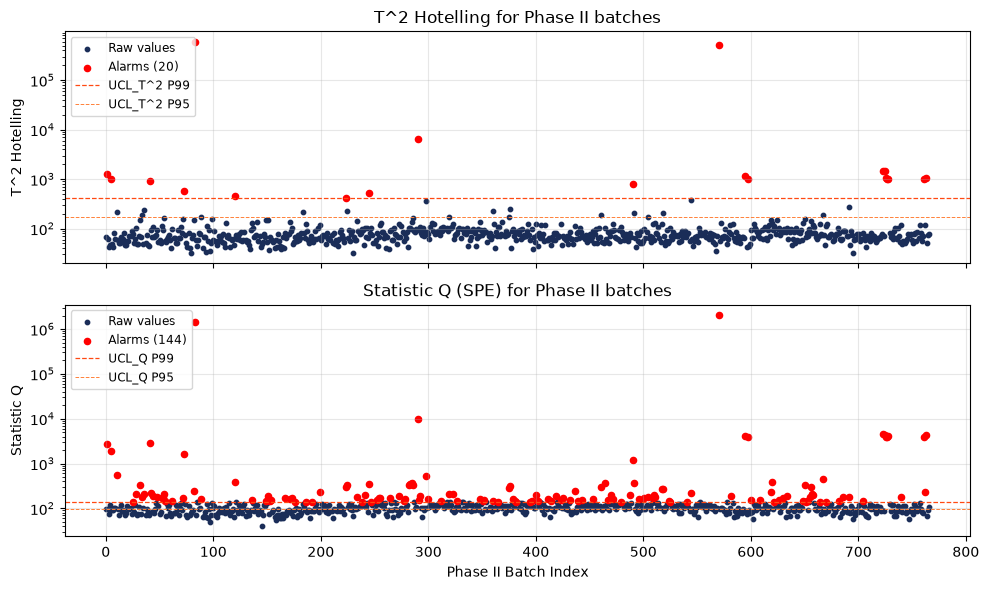

20 alarms are in T^2 Hotelling and 144 in our statistic Q.
There are 144 combined alarms in at least one of both tests.


In [139]:
# T^2 Hotelling:
T2_p1_ic = np.sum((T_p1_ic ** 2) / eigenvalues, axis=1)
T2_p2 = np.sum((T_p2 ** 2) / eigenvalues, axis=1)

# Statistic Q (SPE):
X_p1_ic_hat = pca.inverse_transform(T_p1_ic)
X_p2_hat = pca.inverse_transform(T_p2)
residuals_p1_ic = X_p1_ic_scaled - X_p1_ic_hat
residuals_p2 = X_p2_scaled - X_p2_hat
Q_p1_ic = np.sum(residuals_p1_ic ** 2, axis=1)
Q_p2 = np.sum(residuals_p2 ** 2, axis=1)

# Control Limits (P99 and P95 from Phase I In-Control)
ucl_T2_99 = np.percentile(T2_p1_ic, 99)
ucl_T2_95 = np.percentile(T2_p1_ic, 95)
ucl_Q_99 = np.percentile(Q_p1_ic, 99)
ucl_Q_95 = np.percentile(Q_p1_ic, 95)

# Phase II Alarms (at 99% confidence level)
alarms_T2_99 = T2_p2 > ucl_T2_99
alarms_Q_99 = Q_p2 > ucl_Q_99
alarms_combined_99 = alarms_T2_99 | alarms_Q_99

# Charts
rg = list(range(0, len(T2_p2)))
rg_alarms_T2 = [i for i, b in zip(rg, alarms_T2_99) if b]
rg_alarms_Q  = [i for i, b in zip(rg, alarms_Q_99) if b]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].scatter(rg, T2_p2, s=10, color='#1a2d58', label='Raw values')
axes[0].scatter(rg_alarms_T2, T2_p2[alarms_T2_99], s=20, color='red', label=f'Alarms ({alarms_T2_99.sum()})')
axes[0].axhline(ucl_T2_99, color='#ff4912', linestyle='--', linewidth=0.9, label='UCL_T^2 P99')
axes[0].axhline(ucl_T2_95, color='#ff8139', linestyle='--', linewidth=0.7, label='UCL_T^2 P95')
axes[0].set_yscale('log')
axes[0].set_ylabel('T^2 Hotelling')
axes[0].set_title('T^2 Hotelling for Phase II batches')
axes[0].legend(loc='upper left', fontsize=8.5)
axes[0].grid(alpha=0.3)

axes[1].scatter(rg, Q_p2, s=10, color='#1a2d58', label='Raw values')
axes[1].scatter(rg_alarms_Q, Q_p2[alarms_Q_99], s=20, color='red', label=f'Alarms ({alarms_Q_99.sum()})')
axes[1].axhline(ucl_Q_99, color='#ff4912', linestyle='--', linewidth=0.9, label='UCL_Q P99')
axes[1].axhline(ucl_Q_95, color='#ff8139', linestyle='--', linewidth=0.7, label='UCL_Q P95')
axes[1].set_yscale('log')
axes[1].set_xlabel('Phase II Batch Index')
axes[1].set_ylabel('Statistic Q')
axes[1].set_title('Statistic Q (SPE) for Phase II batches')
axes[1].legend(loc='upper left', fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../img/mspc_t2_q_charts.png', dpi=300)
plt.show()

print(f'{alarms_T2_99.sum()} alarms are in T^2 Hotelling and {alarms_Q_99.sum()} in our statistic Q.')
print(f'There are {alarms_combined_99.sum()} combined alarms in at least one of both tests.')

## 4. Root-Cause Diagnosis: Sensor Contribution Plot
Finally, we identify the defective batches in Phase II that triggered a multivariate alarm and decompose the $Q$ statistic of the first detected defective batch (`target_idx = defective_alarms_idx[0]`, Batch 853) into individual sensor contributions: $\text{Contribution}_m = (X_{i,m} - \hat{X}_{i,m})^2$.

Defective batches detected by MSPC (P99): 11 -> Phase II indices: [ 52  62 120 149 167 238 291 396 511 518 650]

Top 10 sensors contributing to the alarm in Batch 853:
Sensor_211    41.69
Sensor_126    28.00
Sensor_482     4.24
Sensor_589     4.21
Sensor_099     3.94
Sensor_068     3.80
Sensor_486     2.99
Sensor_176     2.64
Sensor_122     2.43
Sensor_127     2.31
dtype: float64


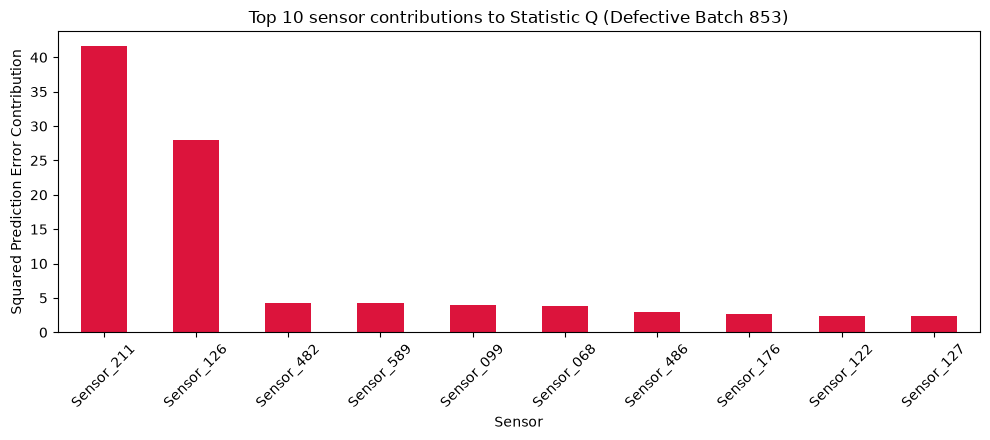

In [137]:
defective_alarms_idx = np.where((df_p2['Defect'] == 1) & alarms_combined_99)[0]
print(f'Defective batches detected by MSPC (P99): {len(defective_alarms_idx)} -> Phase II indices: {defective_alarms_idx}')

target_idx = defective_alarms_idx[0] # we choose the first one, for example
batch_number = 801 + target_idx
contributions = residuals_p2[target_idx] ** 2
contrib_series = pd.Series(contributions, index=sensor_cols).sort_values(ascending=False)

# Top 10 sensors
top10_contrib = contrib_series.head(10)
print(f'\nTop 10 sensors contributing to the alarm in Batch {batch_number}:')
print(top10_contrib.round(2))

plt.figure(figsize=(10, 4.5))
top10_contrib.plot(kind='bar', color='crimson')
plt.title(f'Top 10 sensor contributions to Statistic Q (Defective Batch {batch_number})')
plt.ylabel('Squared Prediction Error Contribution')
plt.xlabel('Sensor')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../img/sensor_contributions.png', dpi=300)
plt.show()